# Two-Tower retail retrieval - offline pipeline notebook
GPU-trained Two-Tower model -> FAISS ANN index -> in-notebook retrieval demo.
This notebook covers the **offline ML pipeline only** (no FastAPI / Redis / HTTP tests). It reuses the modules in `src/`, so results match `python -m src.run_pipeline`. Artifacts go to `outputs/`.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings('ignore')
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, torch, faiss
from IPython.display import Image, display
from src.config import *
print('cwd', os.getcwd())

cwd D:\Ramakrishna_D\Python\GitProjects\machinelearning\recommenders\Two-Tower_model


## 1. Hardware check

In [2]:
from src import check_gpu
hw = check_gpu.main()
print(json.dumps(hw, indent=2)[:1500])

2026-11-19 16:49:05,244 | INFO | gpu | platform               Windows-11-10.0.26300-SP0


2026-11-19 16:49:05,244 | INFO | gpu | python                 3.12.16


2026-11-19 16:49:05,245 | INFO | gpu | nvidia_smi             NVIDIA GeForce RTX 3090, 24576 MiB, 610.60


2026-11-19 16:49:05,245 | INFO | gpu | torch_version          2.15.0+cu132


2026-11-19 16:49:05,246 | INFO | gpu | torch_cuda_available   True


2026-11-19 16:49:05,246 | INFO | gpu | cuda_version           13.2


... (8 outputs left out)

2026-11-19 16:49:05,249 | INFO | gpu | cupy                   False


2026-11-19 16:49:05,250 | INFO | gpu | cudf                   False


2026-11-19 16:49:05,250 | INFO | gpu | ann_backend            faiss-cpu


{
  "platform": "Windows-11-10.0.26300-SP0",
  "python": "3.12.16",
  "nvidia_smi": "NVIDIA GeForce RTX 3090, 24576 MiB, 610.60",
  "torch_version": "2.15.0+cu132",
  "torch_cuda_available": true,
  "cuda_version": "13.2",
  "cudnn": 92600,
  "gpu_name": "NVIDIA GeForce RTX 3090",
  "vram_gb": 24.0,
  "compute_capability": "8.6",
  "amp_matmul_ok": true,
  "faiss_version": "1.16.0",
  "faiss_gpu_count": 0,
  "faiss_gpu_resources": false,
  "cupy": false,
  "cudf": false,
  "ann_backend": "faiss-cpu"
}


## 2. Synthetic data, point-in-time features and temporal split
Latent-factor interactions (view/click/cart/purchase) over 180 days; train < day 126, val 126-153, test >= 153; encoders/scalers fit on train only.

2026-11-19 16:49:06,510 | INFO | data | START generate synthetic data | rss=1171MB vram_alloc=0MB vram_peak=18MB


2026-11-19 16:49:22,351 | INFO | data | END   generate synthetic data | 15.84s | rss=1404MB vram_alloc=0MB vram_peak=18MB


2026-11-19 16:49:22,658 | INFO | data | users=20000 items=5000 events=1200044 positive_rate=0.514 purchases=92294


2026-11-19 16:49:22,658 | INFO | data | START feature engineering + temporal split | rss=1405MB vram_alloc=0MB vram_peak=18MB


2026-11-19 16:49:29,123 | INFO | data | END   feature engineering + temporal split | 6.46s | rss=1628MB vram_alloc=0MB vram_peak=18MB


2026-11-19 16:49:29,123 | INFO | data | dataset summary: {"rows": {"users": 20000, "items": 5000, "events_total": 1200044, "positive_events": 616676, "views": 583368, "purchases": 92294}, "sparsity_pct": 99.423981, "split_boundaries_day": {"train": [0, 126], "val": [126, 153], "test": [153, 180]}, "split_examples": {"train": 411655, "val": 102611, "test": 102410}, "cold_start": {"users_unseen_in_train_pct": 5.064999999999998, "items_unseen_in_train_pct": 2.0000000000000018, "test_examples_from_unseen_users_pct": 14.400937408456205, "test_examples_on_unseen_items_pct": 1.737135045405722, "test_unique_users": 18627}, "train_examples_with_hard_negative_pct": 91.41587008538703, "history_len": 20, "leakage_check": {"train_max_day": 125.0, "val_min_day": 126.0, "passed": true}}


2026-11-19 16:49:29,690 | INFO | data | saved preprocessors, snapshot (19997 users), EDA chart


{
  "rows": {
    "users": 20000,
    "items": 5000,
    "events_total": 1200044,
    "positive_events": 616676,
    "views": 583368,
    "purchases": 92294
  },
  "sparsity_pct": 99.423981,
  "split_boundaries_day": {
    "train": [
      0,
      126
    ],
    "val": [
      126,
      153
    ],
    "test": [
      153,
      180
    ]
  },
  "split_examples": {
    "train": 411655,
    "val": 102611,
    "test": 102410
  },
  "cold_start": {
    "users_unseen_in_train_pct": 5.064999999999998,
    "items_unseen_in_train_pct": 2.0000000000000018,
    "test_examples_from_unseen_users_pct": 14.400937408456205,
    "test_examples_on_unseen_items_pct": 1.737135045405722,
    "test_unique_users": 18627
  },
  "train_examples_with_hard_negative_pct": 91.41587008538703,
  "history_len": 20,
  "leakage_check": {
    "train_max_day": 125.0,
    "val_min_day": 126.0,
    "passed": true
  }
}


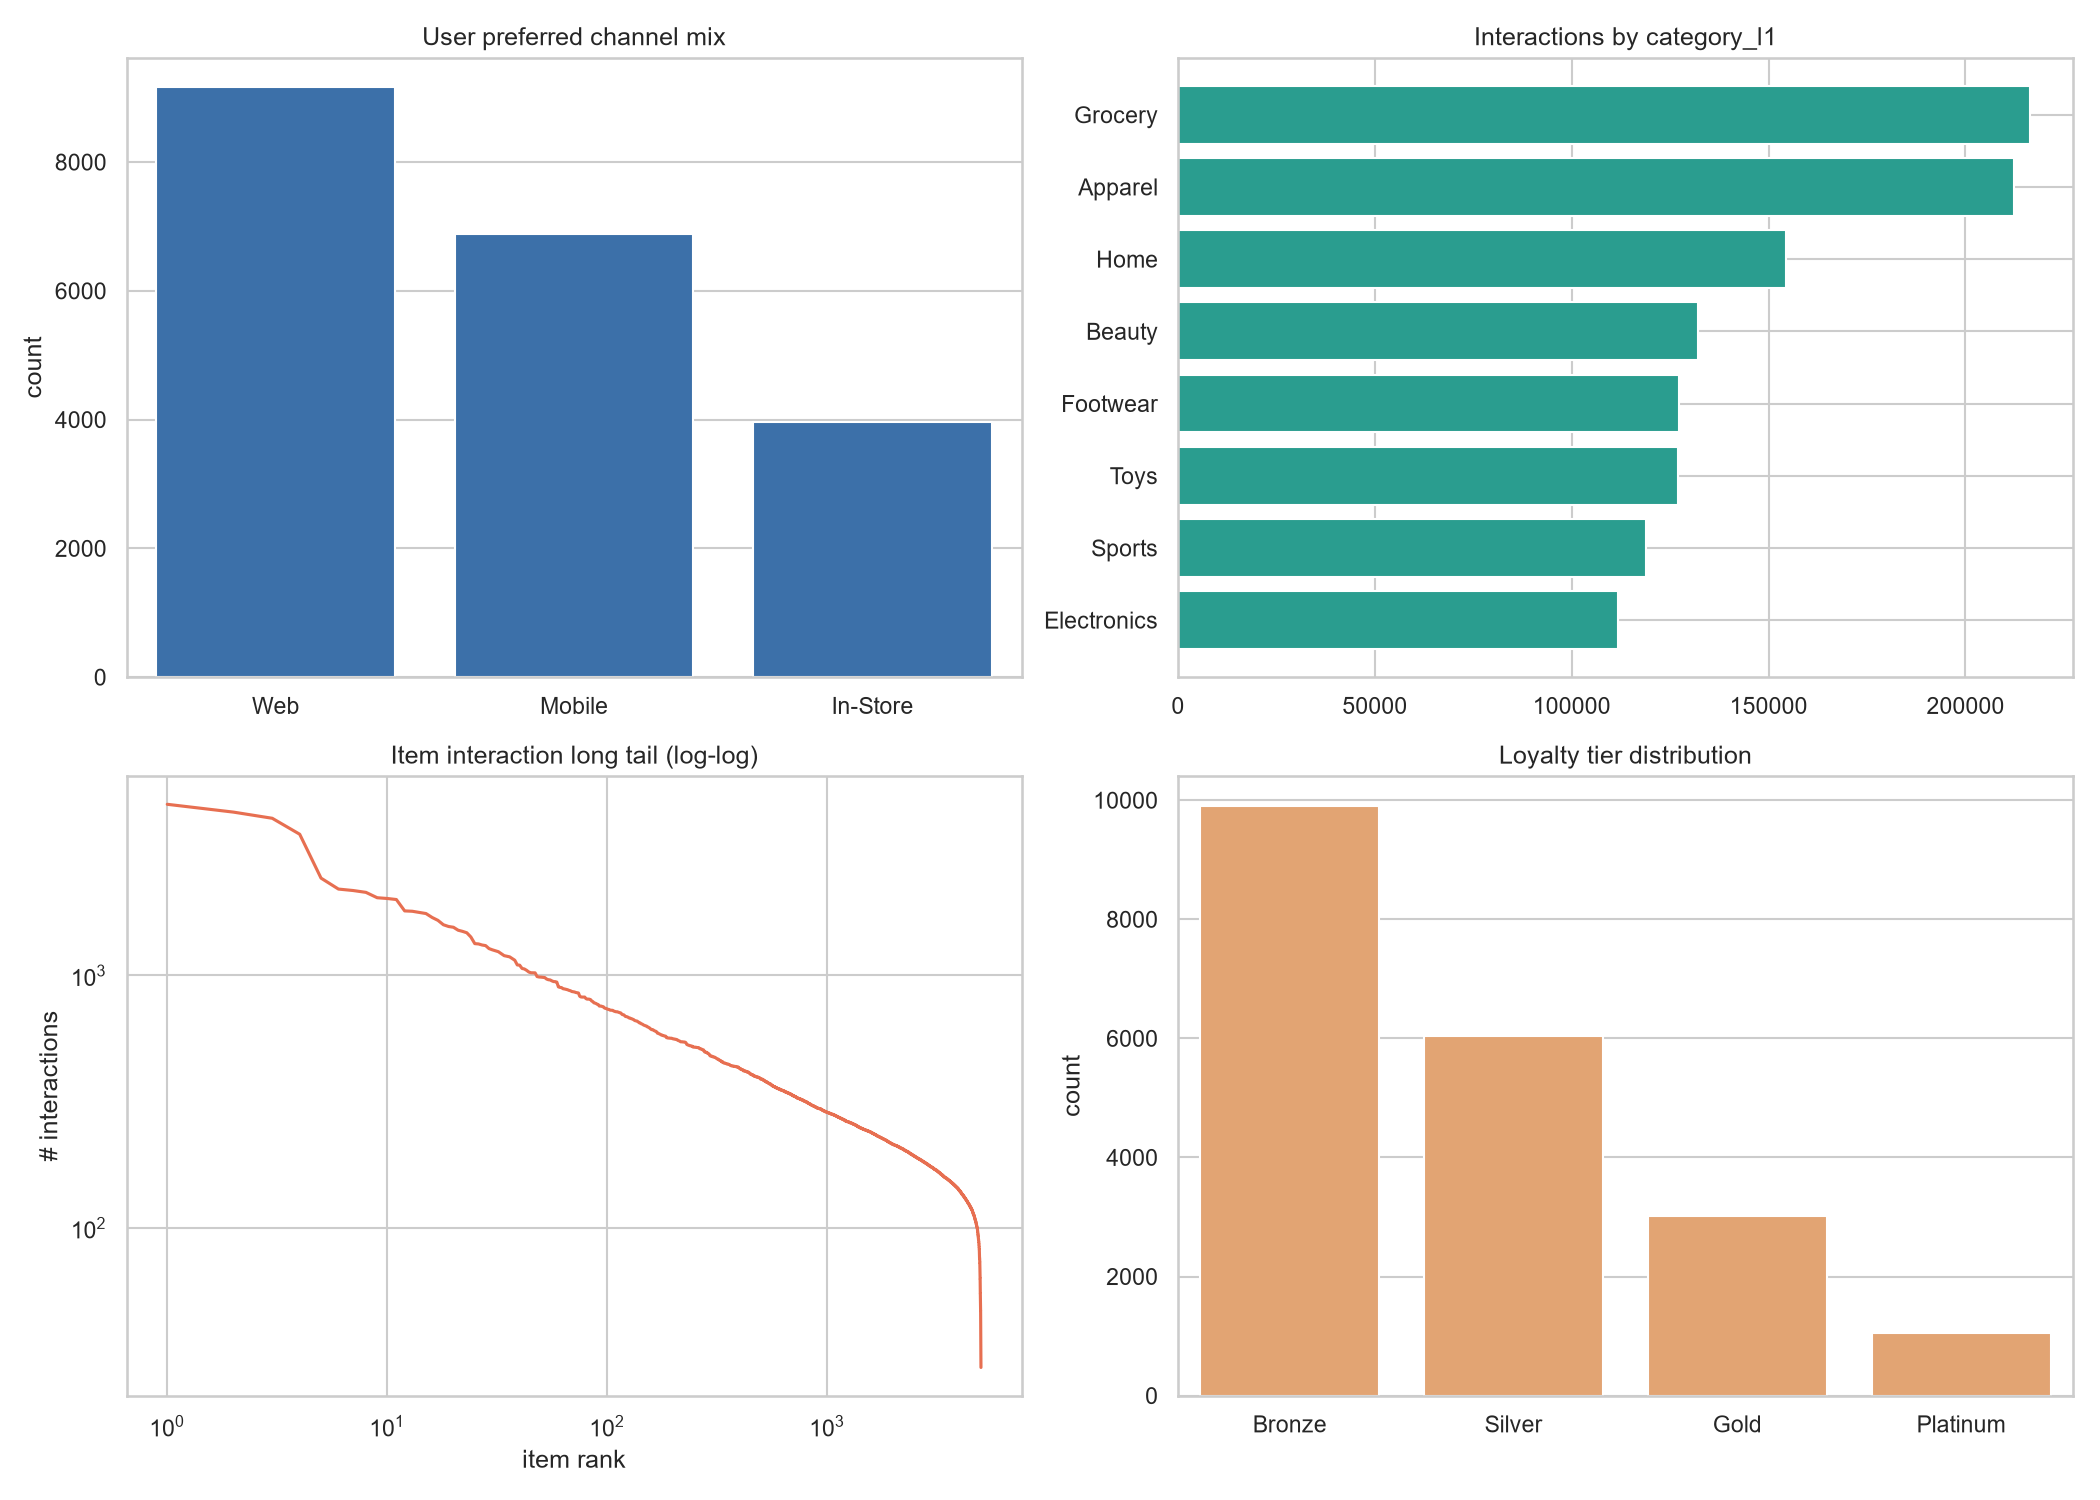

In [3]:
from src import dataset
prep = dataset.main()
print(json.dumps(prep.summary, indent=2))
display(Image('outputs/charts/eda_feature_distributions.png'))

## 3. Model: user tower + item tower (128-d, L2-normalised)

In [4]:
import inspect
from src import model as M
print(inspect.getsource(M.UserTower)); print(inspect.getsource(M.ItemTower)); print(inspect.getsource(M.TwoTower))

class UserTower(nn.Module):
    def __init__(self, sizes: dict, d: int = EMB_DIM, dropout: float = 0.1):
        super().__init__()
        self.uid = nn.Embedding(sizes["user"], 64, padding_idx=0)
        self.tier, self.chan, self.region = (nn.Embedding(sizes[k], 8, padding_idx=0) for k in ("tier", "chan", "region"))
        self.hist = nn.Embedding(sizes["item"], 64, padding_idx=0)       # pooled last-N item sequence
        self.dow, self.hour, self.device = nn.Embedding(8, 4), nn.Embedding(25, 8), nn.Embedding(sizes["device"], 4, padding_idx=0)
        self.mlp = mlp([64 + 24 + 4 + 64 + 16, 512, 256, d], dropout)
        self.dense_proj = nn.Linear(4, 4)

    def forward(self, uid, tier, chan, region, dense, hist, dow, hour, device):
        e = self.hist(hist)
        mask = (hist > 0).unsqueeze(-1).to(e.dtype)
        pooled = (e * mask).sum(1) / mask.sum(1).clamp(min=1.0)
        x = torch.cat([self.uid(uid), self.tier(tier), self.chan(chan), self.region(region), self.dense_pro

## 4. Loss: in-batch InfoNCE + logQ correction + hard negatives

In [5]:
from src import train as T
print(inspect.getsource(T.info_nce))

def info_nce(u, v, tau, log_q, item_ids, v_hard=None, hard_ids=None, hard_valid=None, use_logq=True):
    """Softmax CE over in-batch items. logQ subtracts log sampling prob (popular items are over-represented as
    negatives); same-item collisions are masked; optional per-row hard negative appended as an extra column."""
    logits = (u @ v.T) / tau
    if use_logq:
        logits = logits - log_q[item_ids][None, :]
    same = item_ids[:, None] == item_ids[None, :]
    eye = torch.eye(len(item_ids), dtype=torch.bool, device=u.device)
    logits = logits.masked_fill(same & ~eye, float("-inf"))
    if v_hard is not None:
        hl = (u * v_hard).sum(1) / tau
        if use_logq:
            hl = hl - log_q[hard_ids.clamp(min=0)]
        logits = torch.cat([logits, hl.masked_fill(~hard_valid, float("-inf")).unsqueeze(1)], 1)
    return F.cross_entropy(logits, torch.arange(len(item_ids), device=u.device))



## 5. Training (AMP, cosine LR with warm-up, early stopping on val Recall@50) and export

In [6]:
prep, model, hist, best_epoch = T.main(prep)
h = pd.DataFrame(hist); display(h.tail(8)); print('best epoch', best_epoch)

2026-11-19 16:49:29,720 | INFO | train | START training | rss=1647MB vram_alloc=0MB vram_peak=18MB


2026-11-19 16:49:29,722 | INFO | train | device=cuda amp=True cfg=TrainCfg(epochs=30, batch_size=4096, lr=0.002, weight_decay=1e-05, patience=4, init_temperature=0.07, hard_neg=True, logq=True, dropout=0.1)


2026-11-19 16:49:29,739 | INFO | train | params=2163093 sizes={'tier': 5, 'chan': 4, 'region': 7, 'device': 5, 'cat1': 9, 'cat2': 25, 'brand': 41, 'season': 5, 'user': 18989, 'item': 4902}


2026-11-19 16:49:32,581 | INFO | train | epoch 01 | train_loss=8.4469 val_loss=8.7082 R@10=0.0287 R@50=0.0740 NDCG@10=0.0150 MRR@10=0.0107 | lr=2.00e-03 tau=0.0711 amp_scale=65536.0 | 1.7s peak_vram=613MB


2026-11-19 16:49:32,594 | INFO | train | checkpoint saved (best val Recall@50=0.0740 @ epoch 1)


2026-11-19 16:49:33,872 | INFO | train | epoch 02 | train_loss=8.3344 val_loss=8.7363 R@10=0.0298 R@50=0.0752 NDCG@10=0.0163 MRR@10=0.0121 | lr=1.99e-03 tau=0.0711 amp_scale=65536.0 | 1.3s peak_vram=623MB


... (32 outputs left out)

2026-11-19 16:49:55,910 | INFO | train | exported item_embeddings (5000, 128), user_tower_serving.pt (max diff vs eager 0.00e+00)


2026-11-19 16:49:56,022 | INFO | train | END   export | 0.20s | rss=2483MB vram_alloc=17MB vram_peak=625MB


,epoch,train_loss,val_loss,val_recall_10,val_recall_50,val_ndcg_10,val_mrr_10,lr,temperature,amp_scale,epoch_duration_sec,peak_gpu_memory_mb
11,12,7.538597,8.364546,0.05505,0.12825,0.031918,0.024888,0.001352,0.072263,65536.0,1.242019,624.192383
12,13,7.480698,8.386506,0.05480,0.12715,0.031735,0.024739,0.001253,0.072110,65536.0,1.277550,624.724121
13,14,7.426125,8.375194,0.05450,0.12840,0.031683,0.024773,0.001150,0.071821,65536.0,1.250628,624.724121
14,15,7.373711,8.400376,0.05405,0.12875,0.031725,0.024941,0.001046,0.071397,65536.0,1.181095,624.724121
15,16,7.328588,8.418945,0.05215,0.12730,0.030477,0.023858,0.000942,0.070925,65536.0,1.257205,624.724121
16,17,7.284379,8.421563,0.05335,0.12780,0.030673,0.023807,0.000838,0.070319,65536.0,1.280333,624.724121
17,18,7.244224,8.429409,0.05245,0.12760,0.030096,0.023296,0.000737,0.069610,65536.0,1.242903,624.724121
18,19,7.206840,8.451766,0.05395,0.12755,0.030926,0.023967,0.000639,0.068875,65536.0,1.253359,624.724121


best epoch 15


## 6. Test-set evaluation vs popularity / random baselines

2026-11-19 16:49:56,171 | INFO | evaluate | START test evaluation + charts | rss=2489MB vram_alloc=17MB vram_peak=625MB


2026-11-19 16:49:56,523 | INFO | evaluate | TEST overall: R@10=0.0506 R@50=0.1269 NDCG@10=0.0288 MRR@10=0.0222 | popularity R@50=0.0695 | random R@50=0.0100


2026-11-19 16:49:56,524 | INFO | evaluate |   segment overall            n=102410 R@10=0.0506 R@50=0.1269 NDCG@10=0.0288


2026-11-19 16:49:56,525 | INFO | evaluate |   segment warm_users         n=87662  R@10=0.0523 R@50=0.1301 NDCG@10=0.0298


2026-11-19 16:49:56,526 | INFO | evaluate |   segment cold_start_users   n=14748  R@10=0.0405 R@50=0.1078 NDCG@10=0.0231


2026-11-19 16:49:56,526 | INFO | evaluate |   segment channel_In-Store   n=20552  R@10=0.0519 R@50=0.1282 NDCG@10=0.0292


2026-11-19 16:49:56,527 | INFO | evaluate |   segment channel_Mobile     n=34994  R@10=0.0505 R@50=0.1261 NDCG@10=0.0290


2026-11-19 16:49:56,529 | INFO | evaluate |   segment channel_Web        n=46864  R@10=0.0501 R@50=0.1270 NDCG@10=0.0285


2026-11-19 16:50:03,236 | INFO | evaluate | END   test evaluation + charts | 7.06s | rss=2561MB vram_alloc=17MB vram_peak=625MB


{
  "model": {
    "overall": {
      "n": 102410,
      "recall_10": 0.05059076100587845,
      "recall_50": 0.12693096697330475,
      "ndcg_10": 0.028824545443058014,
      "mrr_10": 0.022241709753870964
    },
    "warm_users": {
      "n": 87662,
      "recall_10": 0.052291758358478546,
      "recall_50": 0.13014760613441467,
      "ndcg_10": 0.02979116141796112,
      "mrr_10": 0.02299647592008114
    },
    "cold_start_users": {
      "n": 14748,
      "recall_10": 0.04048006609082222,
      "recall_50": 0.10781122744083405,
      "ndcg_10": 0.023078981786966324,
      "mrr_10": 0.017755379900336266
    },
    "channel_In-Store": {
      "n": 20552,
      "recall_10": 0.05191708728671074,
      "recall_50": 0.1282113641500473,
      "ndcg_10": 0.0292243380099535,
      "mrr_10": 0.022341681644320488
    },
    "channel_Mobile": {
      "n": 34994,
      "recall_10": 0.050494369119405746,
      "recall_50": 0.1261073350906372,
      "ndcg_10": 0.029022354632616043,
      "mrr_10"

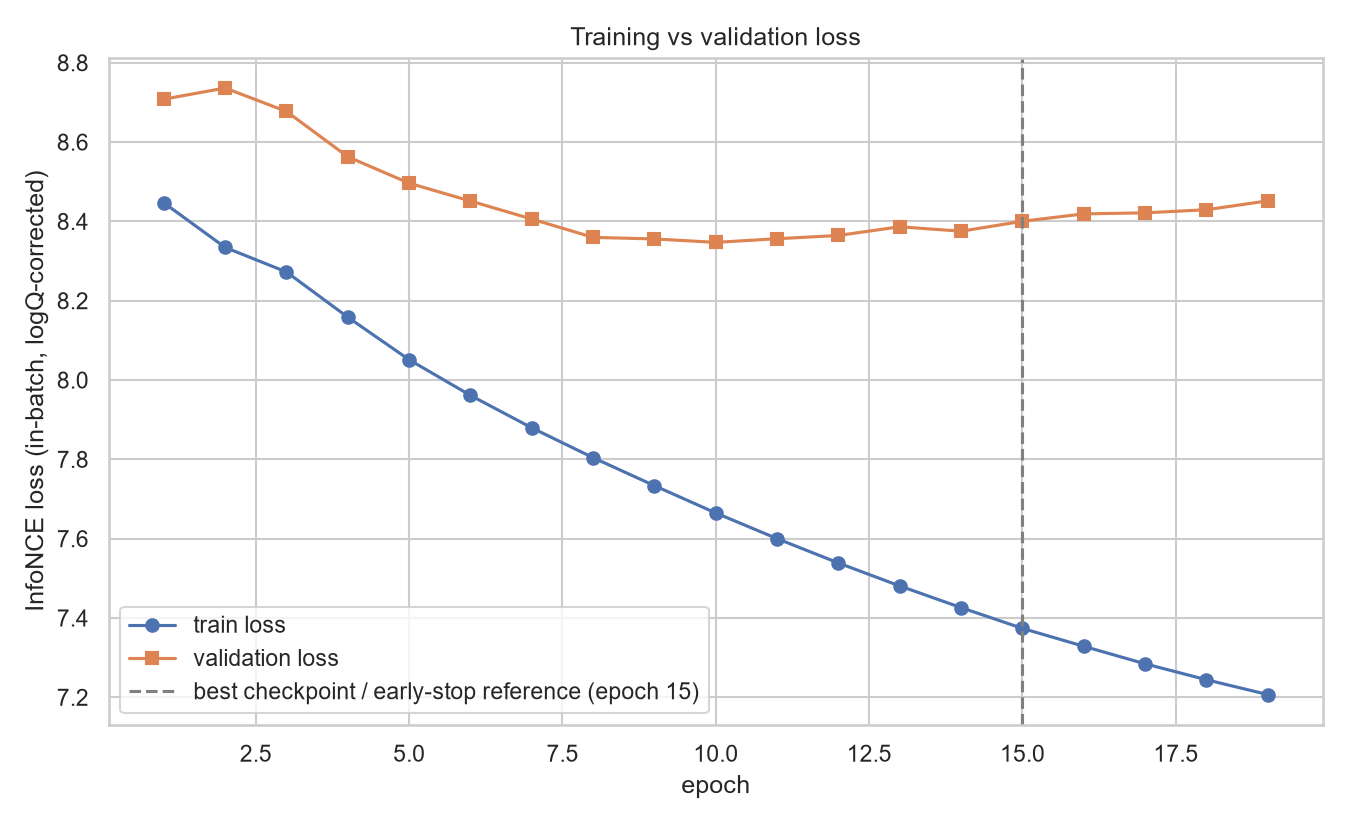

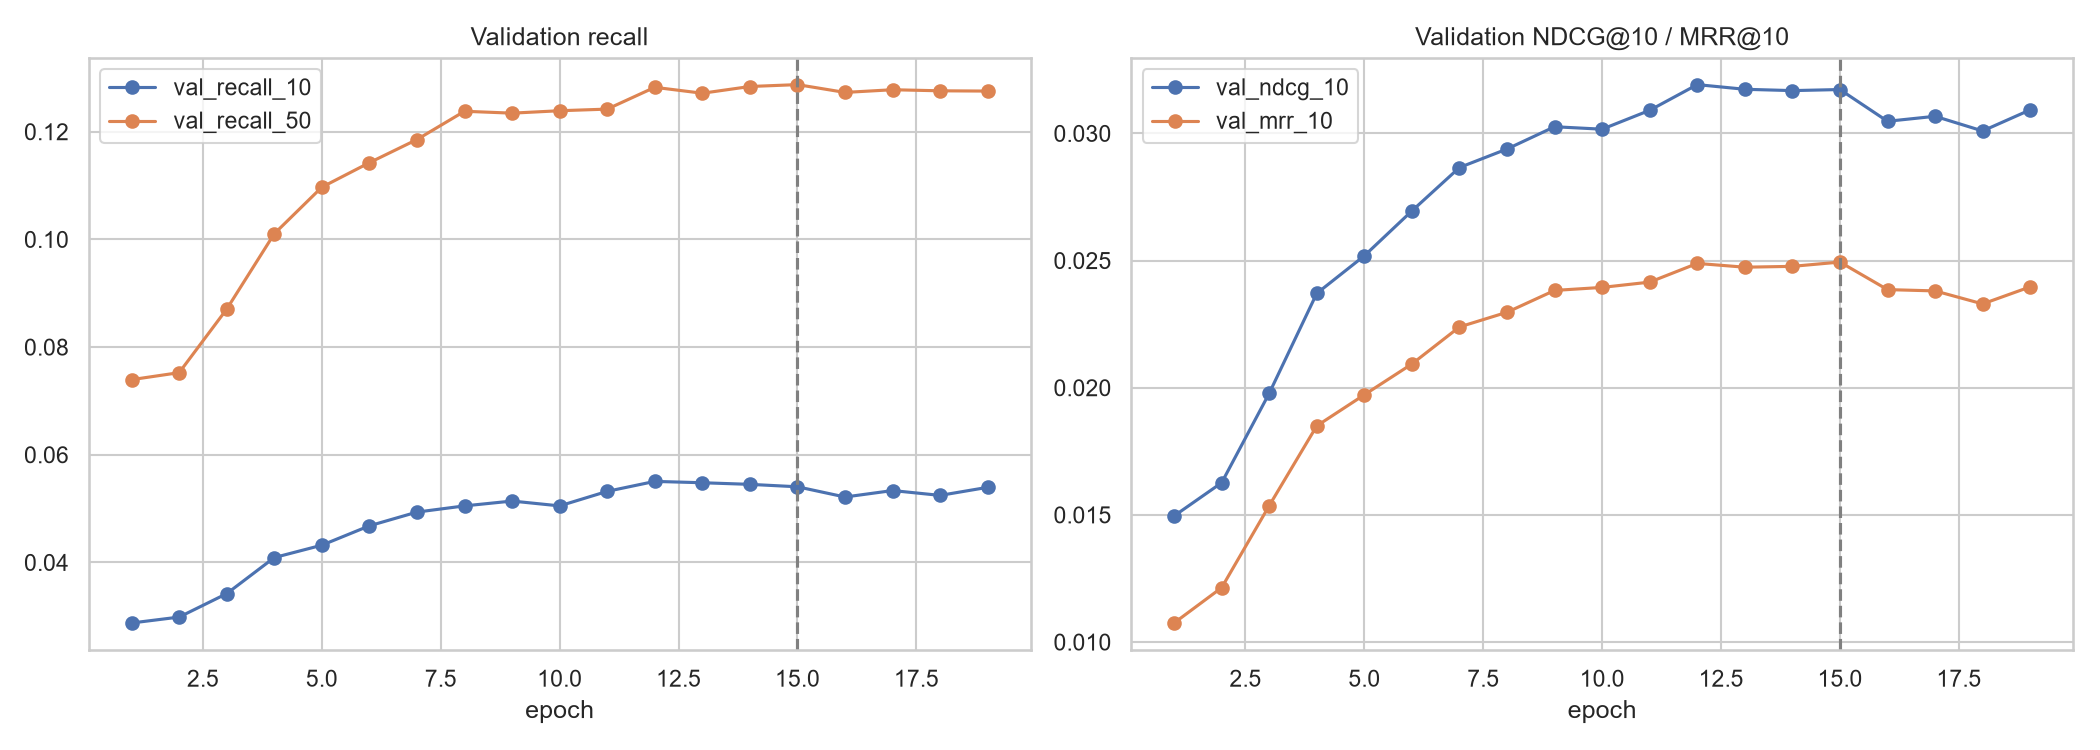

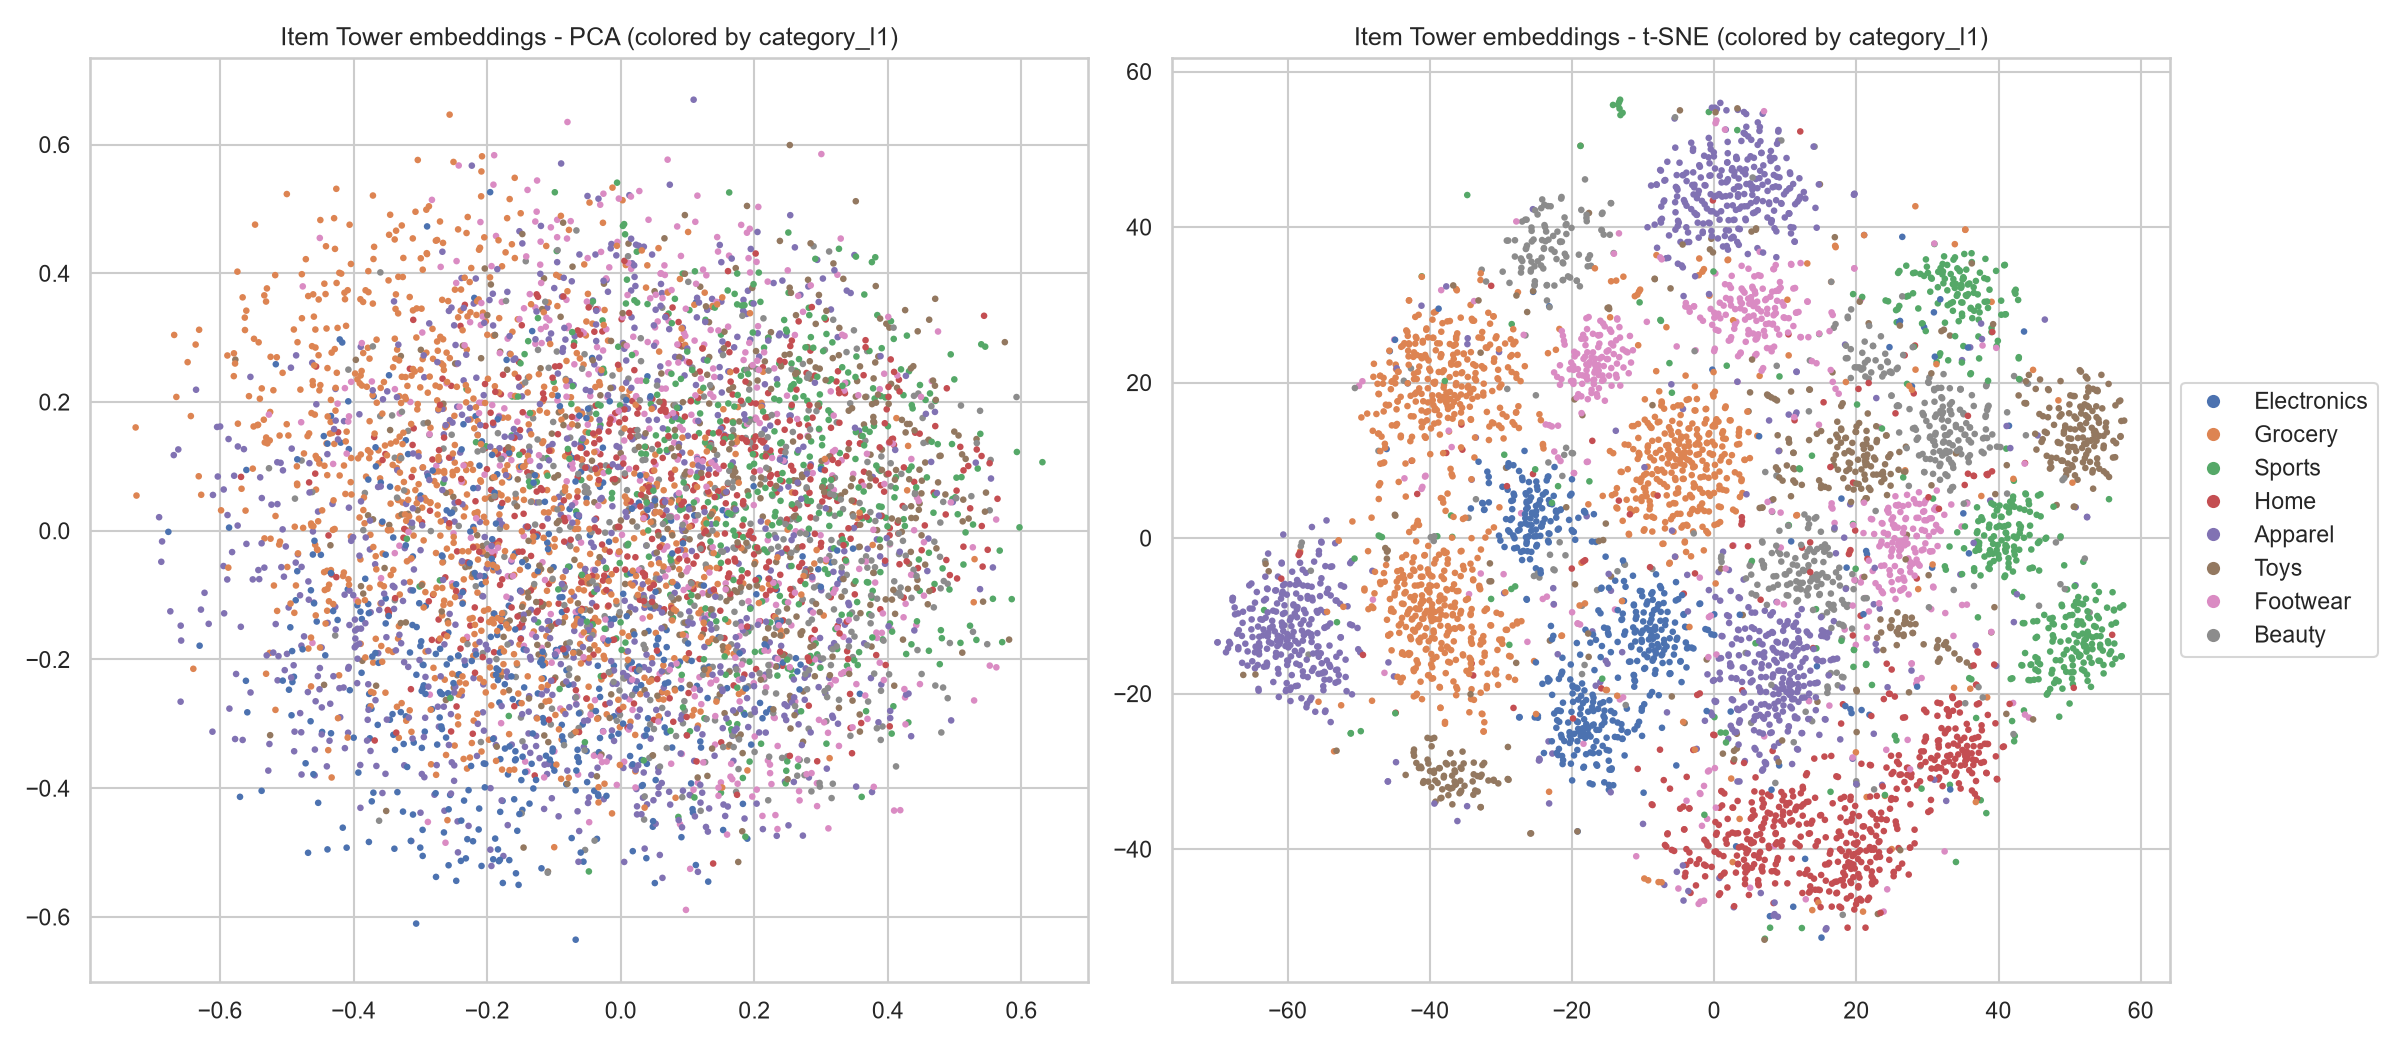

In [7]:
from src import evaluate
res = evaluate.main(prep, model)
print(json.dumps({k: res[k] for k in ('model','popularity_baseline','random_recall_50_expected')}, indent=2)[:2500])
for f in ('training_validation_loss','validation_retrieval_metrics','embedding_space_umap_pca'):
    display(Image(f'outputs/charts/{f}.png'))

## 7. FAISS ANN indexes (Flat / HNSW / IVF-PQ): recall vs latency

2026-11-19 16:50:03,266 | INFO | ann | faiss=1.16.0 gpu_available=False -> backend=faiss-cpu


2026-11-19 16:50:03,275 | INFO | ann | START build IndexFlatIP | rss=2564MB vram_alloc=17MB vram_peak=625MB


2026-11-19 16:50:03,277 | INFO | ann | END   build IndexFlatIP | 0.00s | rss=2567MB vram_alloc=17MB vram_peak=625MB


2026-11-19 16:50:03,345 | INFO | ann | START build IndexHNSWFlat(M=32, efC=200) | rss=2573MB vram_alloc=17MB vram_peak=625MB


2026-11-19 16:50:03,797 | INFO | ann | END   build IndexHNSWFlat(M=32, efC=200) | 0.45s | rss=2577MB vram_alloc=17MB vram_peak=625MB


2026-11-19 16:50:04,134 | INFO | ann | START build IndexIVFPQ(nlist=32, m=16, nbits=6) | rss=2577MB vram_alloc=17MB vram_peak=625MB


... (12 outputs left out)

2026-11-19 16:50:04,520 | INFO | ann | IndexIVFPQ     nprobe=16      recall@10=0.407 qps=    8361 p50=0.122ms p99=0.150ms size=0.14MB [cpu]


2026-11-19 16:50:04,520 | INFO | ann | IndexIVFPQ     nprobe=32      recall@10=0.408 qps=    6501 p50=0.153ms p99=0.177ms size=0.14MB [cpu]


2026-11-19 16:50:05,441 | INFO | ann | persisted retail_items.faiss (HNSW efSearch=32) + item_metadata.parquet


,index,param,recall_at_10,qps,qps_batch,p50_latency_ms,p99_latency_ms,index_size_mb,backend
0,IndexFlatIP,exact,1.00000,18034.525217,1.508000e+05,0.05380,0.072313,2.441449,cpu
1,IndexHNSWFlat,efSearch=8,0.72695,45486.385149,1.370145e+06,0.02160,0.032603,3.735781,cpu
2,IndexHNSWFlat,efSearch=16,0.86135,35544.686940,1.231527e+06,0.02770,0.051110,3.735781,cpu
3,IndexHNSWFlat,efSearch=32,0.95150,33600.795684,6.730381e+05,0.02940,0.037405,3.735781,cpu
4,IndexHNSWFlat,efSearch=64,0.98735,18007.246038,3.621483e+05,0.05345,0.077736,3.735781,cpu
5,IndexHNSWFlat,efSearch=128,0.99685,9679.848691,1.497611e+05,0.10250,0.123107,3.735781,cpu
6,IndexHNSWFlat,efSearch=256,0.99945,4785.270550,9.430315e+04,0.20830,0.239627,3.735781,cpu
7,IndexIVFPQ,nprobe=1,0.25085,41062.365836,3.562142e+05,0.02370,0.035512,0.142658,cpu
8,IndexIVFPQ,nprobe=2,0.32465,32765.399894,3.577882e+05,0.03020,0.039103,0.142658,cpu
9,IndexIVFPQ,nprobe=4,0.37710,22345.070720,3.222999e+05,0.04440,0.056503,0.142658,cpu


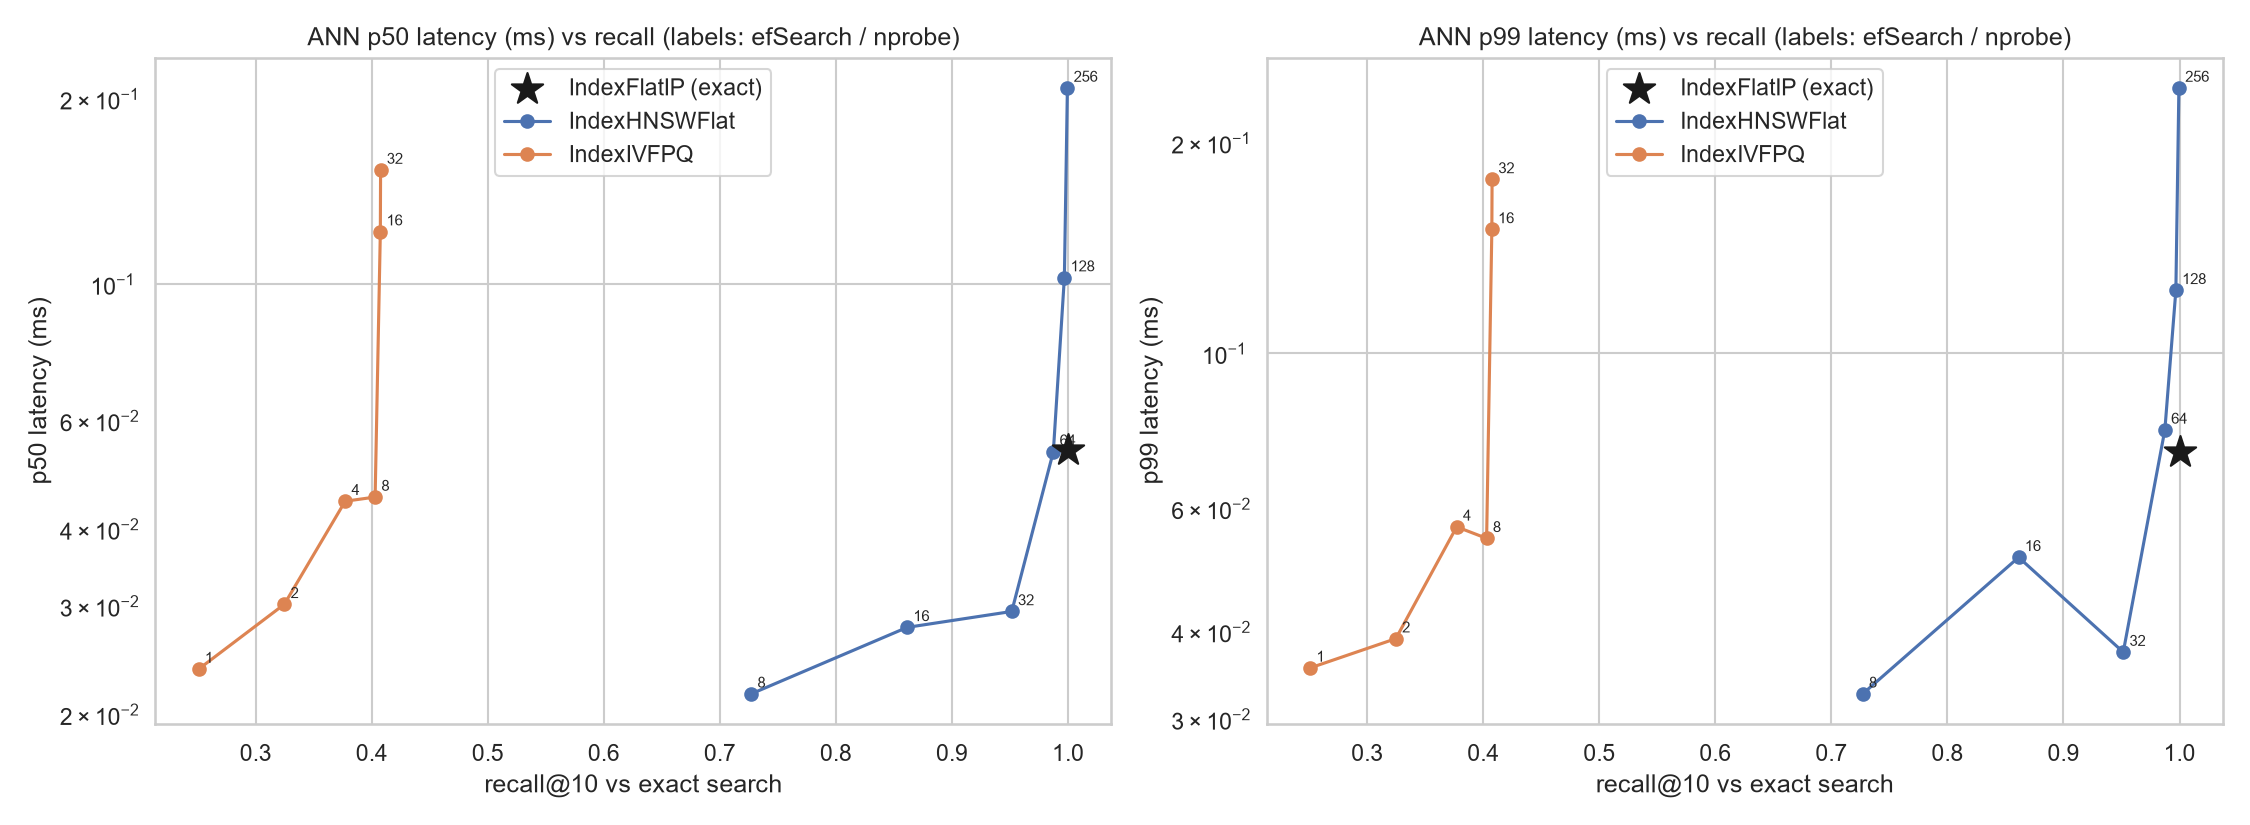

In [8]:
from src import ann_index
df = ann_index.main(prep, model)
display(df)
display(Image('outputs/charts/ann_latency_vs_recall.png'))

## 8. Retrieval demo (what the API does, without HTTP)
Embed a warm user with the user tower, search the HNSW index, drop already-purchased and out-of-stock items; and show a cold-start fallback and item-to-item similarity.

In [9]:
from src.train import U_KEYS, device_of
from src.data_generator import CHANNEL_DEVICE
dev = device_of(); model.eval()
index = faiss.read_index(str(MODELS/'retail_items.faiss')); meta = pd.read_parquet(MODELS/'item_metadata.parquet')
item_emb = np.load(MODELS/'item_embeddings.npy'); seg = np.load(MODELS/'segment_embeddings.npz')
bought = prep.purchased.groupby('user_id').item_id.apply(set)
uid = int(prep.purchased.groupby('user_id').size().idxmax())
s = prep.snapshot[prep.snapshot.user_id == uid].iloc[0]
enc = prep.pre.encode_users([uid],[s.loyalty_tier],[s.preferred_channel],[s.home_region],
    s[['recency_days','frequency_90d','monetary_value_90d','avg_basket_size']].to_numpy(float)[None],
    np.asarray(s.recent_item_history)[None],[3],[14],[CHANNEL_DEVICE[s.preferred_channel][0]])
with torch.no_grad(): q = model.user_tower(*[torch.as_tensor(enc[k]).to(dev) for k in U_KEYS]).cpu().numpy().astype('float32')
def top(q, k=10, excl=()):
    D, I = index.search(q, 60); out = [(int(i), float(d)) for d, i in zip(D[0], I[0]) if i >= 0 and i not in excl and meta.in_stock[i]][:k]
    return meta.loc[[i for i,_ in out], ['item_id','category_l1','category_l2','brand','price']].assign(score=[d for _,d in out])
print('Warm user', uid); display(top(q, 10, bought.get(uid, set())))
print('Cold-start (channel segment embedding)'); display(top(seg['Web'][None].astype('float32'), 10))
print('Similar to item 10'); display(top(item_emb[10:11], 9, {10}))

Warm user 18323


,item_id,category_l1,category_l2,brand,price,score
4790,4790,Beauty,Beauty-3,brand_19,8.74,0.633193
1934,1934,Electronics,Electronics-1,brand_25,340.47,0.632836
4774,4774,Apparel,Apparel-3,brand_02,31.78,0.614144
743,743,Apparel,Apparel-3,brand_00,43.82,0.598755
848,848,Apparel,Apparel-3,brand_00,23.10,0.596249
2813,2813,Apparel,Apparel-3,brand_02,60.12,0.592700
4221,4221,Apparel,Apparel-3,brand_04,46.60,0.592088
2227,2227,Apparel,Apparel-3,brand_00,33.03,0.586678
2250,2250,Beauty,Beauty-1,brand_19,10.86,0.585035
2972,2972,Apparel,Apparel-3,brand_02,62.37,0.577117


Cold-start (channel segment embedding)


,item_id,category_l1,category_l2,brand,price,score
533,533,Home,Home-1,brand_23,24.45,0.563121
2060,2060,Toys,Toys-2,brand_37,32.13,0.560010
1631,1631,Sports,Sports-3,brand_32,25.17,0.557215
2227,2227,Apparel,Apparel-3,brand_00,33.03,0.515889
1934,1934,Electronics,Electronics-1,brand_25,340.47,0.506724
531,531,Electronics,Electronics-1,brand_25,336.79,0.502544
503,503,Beauty,Beauty-1,brand_16,14.17,0.497969
3551,3551,Beauty,Beauty-2,brand_15,15.64,0.495573
4367,4367,Home,Home-2,brand_21,29.58,0.493770
4536,4536,Home,Home-2,brand_21,28.90,0.488825


Similar to item 10


,item_id,category_l1,category_l2,brand,price,score
2650,2650,Toys,Toys-2,brand_37,23.84,0.700513
2838,2838,Grocery,Grocery-2,brand_14,3.27,0.690094
4188,4188,Apparel,Apparel-3,brand_04,23.75,0.669006
3689,3689,Grocery,Grocery-2,brand_13,6.25,0.662299
2476,2476,Apparel,Apparel-1,brand_00,60.93,0.656282
1625,1625,Electronics,Electronics-3,brand_25,276.71,0.653720
1835,1835,Apparel,Apparel-3,brand_04,26.47,0.651187
2472,2472,Electronics,Electronics-2,brand_28,461.84,0.647595
1007,1007,Grocery,Grocery-2,brand_10,4.81,0.647130
